# Pairwise model complementarity for outbreak warnings

Compare DP + XGBoost, DP + RF, and XGBoost + RF. OR: either model alerts. AND: both alert on the same ZIP/date. Reuse existing forecasts and calibration thresholds. No model retraining. Same 585 ZIPs and 1,131 eligible events, September–December 2020. These are exploratory validation results.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir(): ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"mentor_followup_outputs"/"2026-11-04"/"pair_warning_complementarity"
print(OUTPUT.resolve())

In [2]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score,precision_recall_curve

def event_labels(counts):
    """Causal labels; onset is confirmation, never backdated."""
    s=pd.Series(np.asarray(counts,dtype=float))
    ma=s.rolling(3,min_periods=3).mean()
    hist=ma.shift(3).rolling(28,min_periods=28)
    mean,sd=hist.mean(),hist.std(ddof=1)
    threshold=mean+2*sd
    qualify=(ma>threshold)&(s.rolling(3).sum()>=5)&threshold.notna()
    valid=threshold.notna().to_numpy()
    # Smooth continuous excess with the same sign as the two qualification gates.
    scale=np.maximum(sd.to_numpy(),1.)
    margin=np.minimum((ma.to_numpy()-threshold.to_numpy())/scale,
                      (s.rolling(3).sum().to_numpy()-5+1e-9)/(3*scale))
    active=np.zeros(len(s),bool);onset=np.zeros(len(s),bool)
    in_event=False;off=0
    for k in range(len(s)):
        if in_event:
            off=0 if qualify.iloc[k] else off+1
            if off>=7:in_event=False;off=0
        elif k>0 and qualify.iloc[k] and qualify.iloc[k-1]:
            in_event=True;onset[k]=True
        active[k]=in_event
    return dict(ma=ma.to_numpy(),threshold=threshold.to_numpy(),sd=sd.to_numpy(),
                qualify=qualify.to_numpy(),valid=valid,margin=margin,active=active,onset=onset)

def warning_events(score,eligible,truth_onset,origins,dates,threshold):
    """Seven-day issue cooldown. One alarm matches at most one event."""
    rows=[];events=[]
    for z in range(len(score)):
        event_dates=dates[truth_onset[z]]
        # Denominator: events with at least one scored eligible origin 1..3 days before.
        covered=[d for d in event_dates if np.any(eligible[z]&((d-origins).astype('timedelta64[D]').astype(int)>=1)&((d-origins).astype('timedelta64[D]').astype(int)<=3))]
        matched=set();last=None
        for k,d in enumerate(origins):
            if not eligible[z,k] or not score[z,k]>threshold:continue
            if last is not None and (d-last).astype('timedelta64[D]').astype(int)<7:continue
            last=d
            candidates=[e for e in covered if e not in matched and 1<=int((e-d)/np.timedelta64(1,'D'))<=3]
            target=min(candidates) if candidates else None
            if target is not None:matched.add(target)
            rows.append(dict(region_index=z,forecast_origin=str(d)[:10],matched_event_date=str(target)[:10] if target is not None else '',
                             true_warning=target is not None,lead_days=float((target-d)/np.timedelta64(1,'D')) if target is not None else np.nan))
        for d in covered:events.append(dict(region_index=z,event_date=str(d)[:10],detected=d in matched))
    alarms=pd.DataFrame(rows,columns=['region_index','forecast_origin','matched_event_date','true_warning','lead_days'])
    ev=pd.DataFrame(events,columns=['region_index','event_date','detected'])
    tp=int(alarms.true_warning.sum()) if len(alarms) else 0;fp=len(alarms)-tp
    exposure=int(eligible.sum())
    metrics=dict(events=len(ev),detected_events=int(ev.detected.sum()) if len(ev) else 0,warning_episodes=len(alarms),false_warning_episodes=fp,
                 event_recall=tp/len(ev) if len(ev) else np.nan,warning_precision=tp/len(alarms) if len(alarms) else np.nan,
                 false_warnings_per_30_at_risk_zip_days=fp*30/exposure if exposure else np.nan,
                 mean_lead_days=float(alarms.lead_days.mean()) if len(alarms) else np.nan,
                 median_lead_days=float(alarms.lead_days.median()) if len(alarms) else np.nan,at_risk_zip_days=exposure)
    return metrics,alarms,ev


from pathlib import Path
import itertools,json
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
NAMES=['Dynamic Panel FE','XGBoost','Random Forest']
def run_pairs(root,output):
 root=Path(root);out=Path(output);out.mkdir(parents=True,exist_ok=True)
 warning=root/'outbreak_task_outputs/case_surge_v1_20261101'
 frames=[pd.read_csv(warning/(m.lower().replace(' ','_')+'_risk_scores.csv.gz'),dtype={'zip':str}).sort_values(['zip','forecast_origin']).reset_index(drop=True) for m in NAMES]
 for f in frames[1:]:
  for c in ['zip','forecast_origin','eligible','event_in_next_3_days']: assert f[c].equals(frames[0][c]),c
 ids=np.sort(frames[0].zip.unique());dates=np.sort(frames[0].forecast_origin.unique()).astype('datetime64[D]');n=len(dates)
 assert len(ids)==585
 eligible=frames[0].eligible.to_numpy().reshape(len(ids),n)
 thresholds=pd.read_csv(warning/'warning_metrics.csv').query("phase=='calibration'").set_index('model').threshold.reindex(NAMES).to_numpy()
 votes=np.stack([f.risk_score.to_numpy().reshape(len(ids),n)>t for f,t in zip(frames,thresholds)])
 labels=pd.read_csv(warning/'daily_event_labels_2020.csv.gz',dtype={'zip':str},parse_dates=['date'])
 pivot=labels.pivot(index='zip',columns='date',values='onset').reindex(ids);calendar=pivot.columns.to_numpy().astype('datetime64[D]');onsets=pivot.to_numpy(bool)
 mask=(dates>=np.datetime64('2020-09-01'))&(dates<=np.datetime64('2020-12-28'))
 rules=[(name,votes[j]) for j,name in enumerate(NAMES)]
 for i,j in itertools.combinations(range(3),2):
  for logic in ['OR','AND']:rules.append((NAMES[i]+' + '+NAMES[j]+' '+logic,(votes[i]|votes[j]) if logic=='OR' else (votes[i]&votes[j])))
 rows=[];evs={}
 for name,v in rules:
  met,alarms,ev=warning_events(v[:,mask].astype(float),eligible[:,mask],onsets,dates[mask],calendar,.5)
  assert met['events']==1131 and met['at_risk_zip_days']==55541
  rows.append(dict(rule=name,**met));key=ev.set_index(['region_index','event_date']).detected;evs[name]=key
  alarms['zip']=alarms.region_index.map(dict(enumerate(ids)));ev['zip']=ev.region_index.map(dict(enumerate(ids)))
  slug=name.replace(' + ','__').replace(' ','_')
  alarms.rename(columns={'forecast_origin':'daily_forecast_date'}).to_csv(out/(slug+'_warnings.csv'),index=False)
  ev.to_csv(out/(slug+'_events.csv'),index=False)
 metrics=pd.DataFrame(rows);metrics.to_csv(out/'pair_warning_metrics.csv',index=False);m=metrics.set_index('rule');comparison=[];rescue=[]
 for i,j in itertools.combinations(range(3),2):
  a,b=NAMES[i],NAMES[j]
  for source,target in [(a,b),(b,a)]:
   miss=~evs[source];rescued=miss&evs[target]
   rescue.append(dict(missed_by=source,rescued_by=target,missed_events=int(miss.sum()),rescued_events=int(rescued.sum()),rescue_rate=rescued.sum()/miss.sum()))
  for logic in ['OR','AND']:
   name=a+' + '+b+' '+logic
   for baseline in [a,b]:
    gained=(~evs[baseline])&evs[name];lost=evs[baseline]&(~evs[name])
    comparison.append(dict(pair=a+' + '+b,logic=logic,baseline=baseline,event_recall_delta_pp=100*(m.loc[name,'event_recall']-m.loc[baseline,'event_recall']),warning_precision_delta_pp=100*(m.loc[name,'warning_precision']-m.loc[baseline,'warning_precision']),detected_events_delta=int(m.loc[name,'detected_events']-m.loc[baseline,'detected_events']),false_warnings_delta=int(m.loc[name,'false_warning_episodes']-m.loc[baseline,'false_warning_episodes']),newly_detected_events=int(gained.sum()),previously_detected_now_missed=int(lost.sum())))
 comparisons=pd.DataFrame(comparison);comparisons.to_csv(out/'pair_vs_members.csv',index=False);pd.DataFrame(rescue).to_csv(out/'individual_event_rescue.csv',index=False)
 plt.rcParams.update({'font.family':'Arial','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
 fig,axs=plt.subplots(1,2,figsize=(13,5));short=['DP','XGB','RF','DP+XGB OR','DP+XGB AND','DP+RF OR','DP+RF AND','XGB+RF OR','XGB+RF AND']
 for ax,k,title in zip(axs,['event_recall','warning_precision'],['Detected events / 1,131 eligible events','Correct warnings / issued warnings']):
  bars=ax.bar(range(9),metrics[k],color=['#64748B','#2563EB','#087F78']+['#8DAEC3','#173654']*3);ax.bar_label(bars,labels=[f'{v:.1%}' for v in metrics[k]],fontsize=9,padding=3);ax.set(xticks=range(9),xticklabels=short,ylim=(0,1.12),title=title);ax.tick_params(axis='x',rotation=55);ax.set_yticks(np.arange(0,1.01,.2));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
 fig.tight_layout();fig.savefig(out/'pair_detection_precision.png',dpi=220);plt.close(fig)
 text='# Pairwise warning combinations\n\n'+metrics.to_markdown(index=False)+'\n\n## Changes against members\n\n'+comparisons.to_markdown(index=False)+'\n\n## Original individual rescue\n\n'+pd.DataFrame(rescue).to_markdown(index=False)+'\n\nSame-ZIP-date OR/AND precedes shared seven-day cooldown and one-to-one event matching. Original thresholds retained. Exploratory 2020 validation. Changes in percentage points. No retraining or significance claim.'
 (out/'RESULTS.md').write_text(text,encoding='utf-8')
 (out/'protocol.json').write_text(json.dumps(dict(assessment_start='2020-09-01',assessment_last_forecast_date='2020-12-28',regions=585,events=1131,at_risk_zip_dates=55541,horizon_days=[1,2,3],cooldown_days=7,thresholds=dict(zip(NAMES,map(float,thresholds))),retrained=False,event_rule='Original Notebook 27 case_surge_v1',purpose='Exploratory paired warning comparison'),indent=2))
 return metrics,comparisons,pd.DataFrame(rescue)


In [3]:
metrics,comparison,rescue=run_pairs(ROOT,OUTPUT)
display(metrics.round(4))

,rule,events,detected_events,warning_episodes,false_warning_episodes,event_recall,warning_precision,false_warnings_per_30_at_risk_zip_days,mean_lead_days,median_lead_days,at_risk_zip_days
0,Dynamic Panel FE,1131,889,1309,420,0.7860,0.6791,0.2269,1.3048,1.0,55541
1,XGBoost,1131,825,986,161,0.7294,0.8367,0.0870,1.1358,1.0,55541
2,Random Forest,1131,897,1170,273,0.7931,0.7667,0.1475,1.2308,1.0,55541
3,Dynamic Panel FE + XGBoost OR,1131,895,1321,426,0.7913,0.6775,0.2301,1.3117,1.0,55541
4,Dynamic Panel FE + XGBoost AND,1131,820,974,154,0.7250,0.8419,0.0832,1.1280,1.0,55541
5,Dynamic Panel FE + Random Forest OR,1131,910,1377,467,0.8046,0.6609,0.2522,1.3341,1.0,55541
6,Dynamic Panel FE + Random Forest AND,1131,876,1101,225,0.7745,0.7956,0.1215,1.1986,1.0,55541
7,XGBoost + Random Forest OR,1131,900,1182,282,0.7958,0.7614,0.1523,1.2344,1.0,55541
8,XGBoost + Random Forest AND,1131,822,974,152,0.7268,0.8439,0.0821,1.1302,1.0,55541


,pair,logic,baseline,event_recall_delta_pp,warning_precision_delta_pp,detected_events_delta,false_warnings_delta,newly_detected_events,previously_detected_now_missed
0,Dynamic Panel FE + XGBoost,OR,Dynamic Panel FE,0.531,-0.163,6,6,7,1
1,Dynamic Panel FE + XGBoost,OR,XGBoost,6.189,-15.920,70,265,124,54
2,Dynamic Panel FE + XGBoost,AND,Dynamic Panel FE,-6.101,16.274,-69,-266,54,123
3,Dynamic Panel FE + XGBoost,AND,XGBoost,-0.442,0.518,-5,-7,2,7
4,Dynamic Panel FE + Random Forest,OR,Dynamic Panel FE,1.857,-1.829,21,47,32,11
5,Dynamic Panel FE + Random Forest,OR,Random Forest,1.149,-10.581,13,194,60,47
6,Dynamic Panel FE + Random Forest,AND,Dynamic Panel FE,-1.149,11.650,-13,-195,47,60
7,Dynamic Panel FE + Random Forest,AND,Random Forest,-1.857,2.897,-21,-48,11,32
8,XGBoost + Random Forest,OR,XGBoost,6.631,-7.529,75,121,97,22
9,XGBoost + Random Forest,OR,Random Forest,0.265,-0.525,3,9,4,1


,missed_by,rescued_by,missed_events,rescued_events,rescue_rate
0,Dynamic Panel FE,XGBoost,242,61,0.2521
1,XGBoost,Dynamic Panel FE,306,125,0.4085
2,Dynamic Panel FE,Random Forest,242,79,0.3264
3,Random Forest,Dynamic Panel FE,234,71,0.3034
4,XGBoost,Random Forest,306,98,0.3203
5,Random Forest,XGBoost,234,26,0.1111


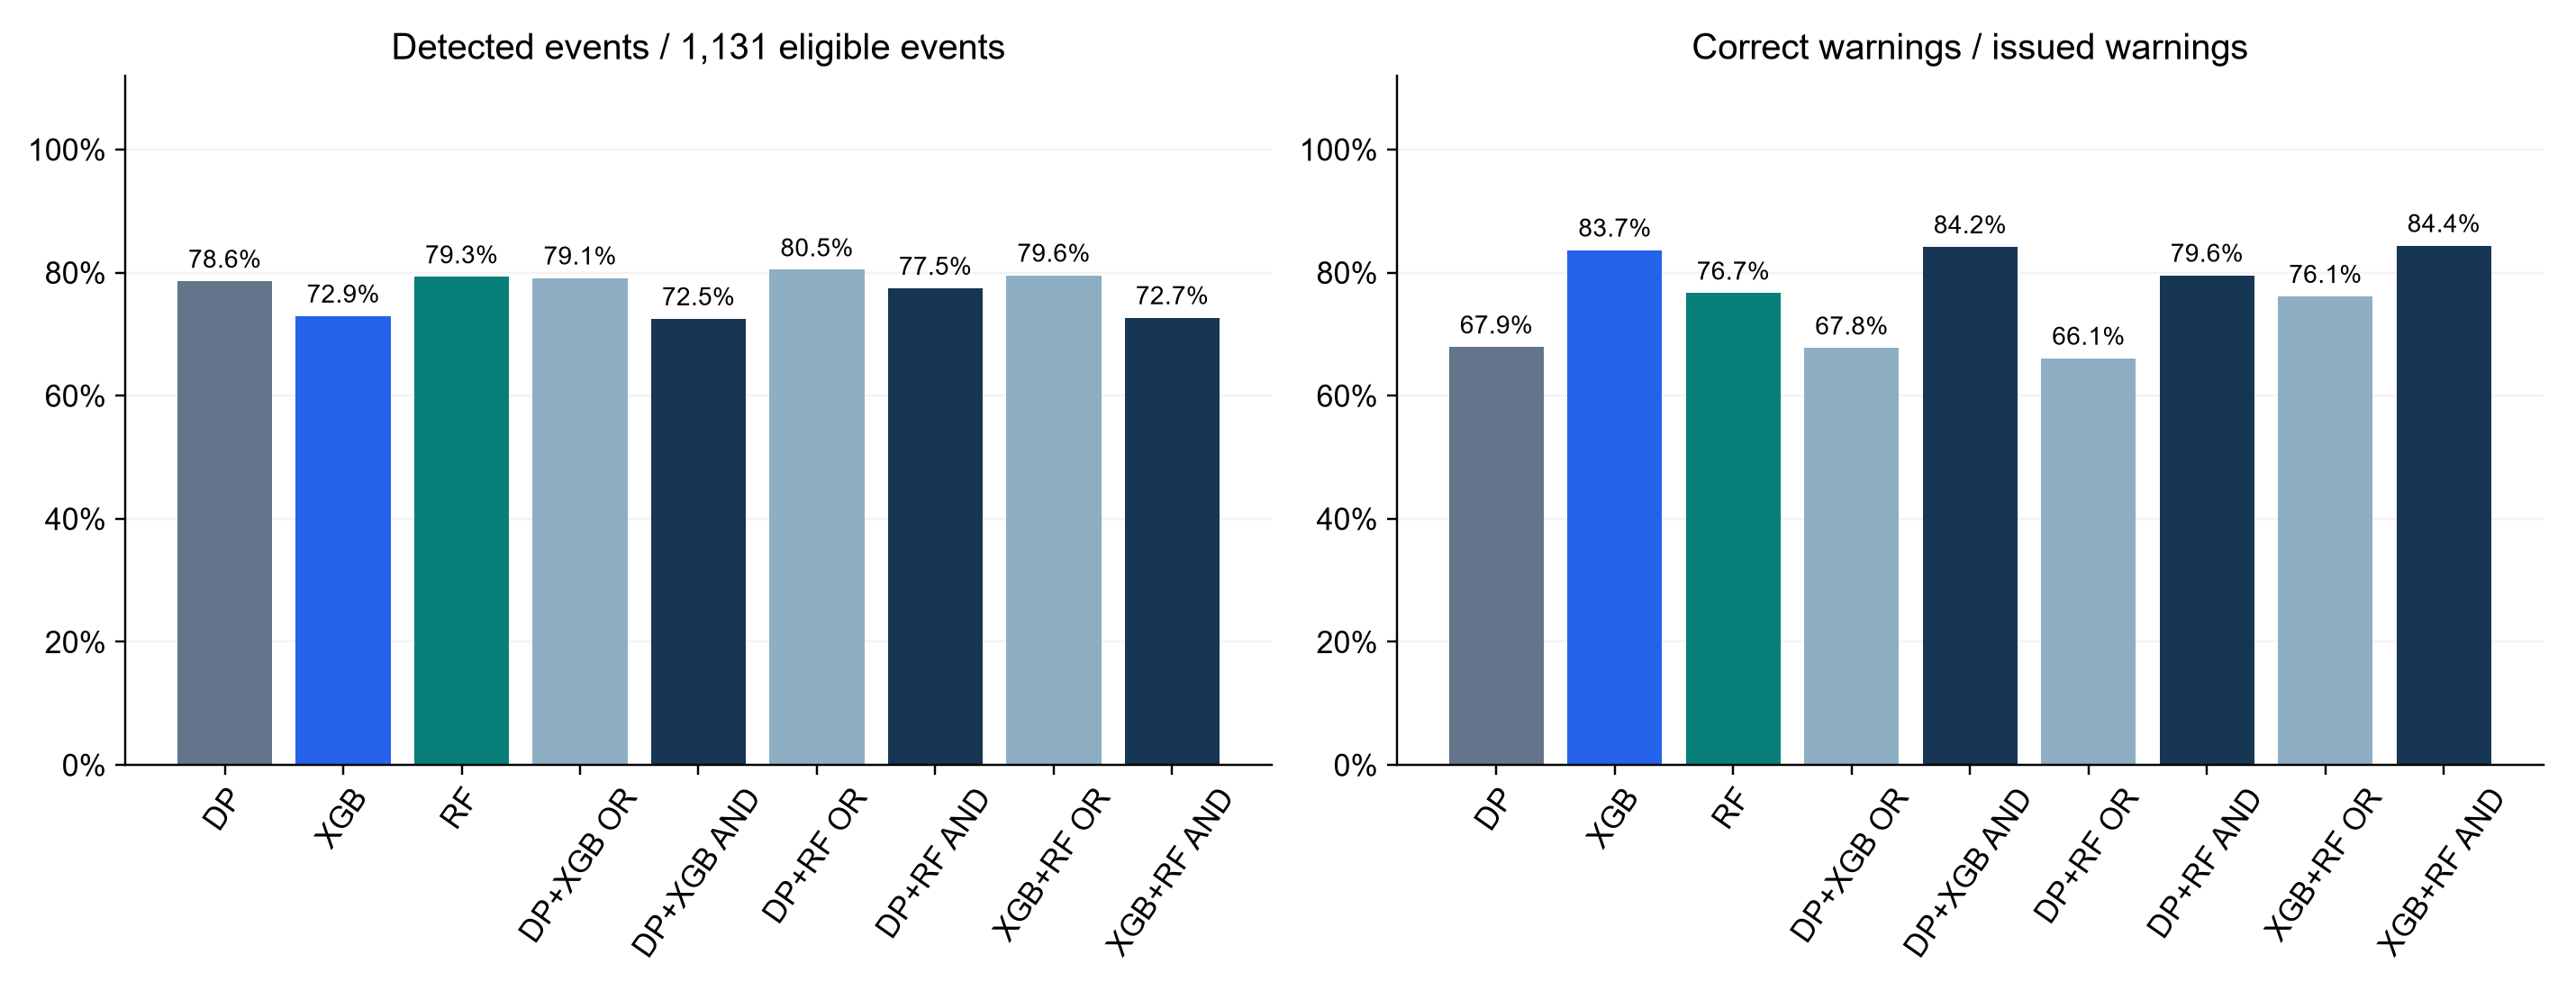

In [4]:
display(comparison.round(3))
display(rescue.round(4))
from IPython.display import Image,display
display(Image(filename=str(OUTPUT/"pair_detection_precision.png")))

## Reading the results
Positive recall delta means more events detected. Positive precision delta means a higher proportion of warnings are correct. Read these alongside false warning counts and lost events. The rescue table asks how often an original individual model detects events missed by another; combined warnings have separately recomputed cooldown and matching, so the two analyses answer different questions. No claim of statistically significant differences. The original case-surge definition remains unchanged.

## Incremental value from each starting model

Start from DP, XGBoost or Random Forest separately. Add one other model or both. All use OR daily votes, followed by the shared cooldown and event matching. Report percentage-point changes against the starting model. Three-model OR uses the verified Notebook 34 results on the same assessment cohort.

In [5]:
# Incremental value: each model is the starting warning system.
all_three = pd.read_csv(ROOT/'mentor_followup_outputs'/'2026-11-04'/'model_complementarity'/'warning_vote_metrics.csv').set_index('rule').loc['At least 1 model votes']
m = metrics.set_index('rule')
rows=[]
for anchor in NAMES:
    others=[x for x in NAMES if x != anchor]
    for added in [[], [others[0]], [others[1]], others]:
        if not added: value=m.loc[anchor]
        elif len(added)==2: value=all_three
        else:
            pair=[x for x in NAMES if x in [anchor]+added]
            value=m.loc[' + '.join(pair)+' OR']
        reference=m.loc[anchor]
        rows.append(dict(starting_model=anchor,added_models='None' if not added else ' + '.join(added),event_detection_pct=100*value.event_recall,correct_warning_pct=100*value.warning_precision,detection_change_pp=100*(value.event_recall-reference.event_recall),precision_change_pp=100*(value.warning_precision-reference.warning_precision),detected_events=int(value.detected_events),false_warnings=int(value.false_warning_episodes),extra_events=int(value.detected_events-reference.detected_events),extra_false_warnings=int(value.false_warning_episodes-reference.false_warning_episodes)))
incremental=pd.DataFrame(rows)
incremental.to_csv(OUTPUT/'incremental_value_by_starting_model.csv',index=False)
for anchor in NAMES:
    print('Starting model:',anchor)
    display(incremental.loc[incremental.starting_model.eq(anchor)].round(3))


Starting model: Dynamic Panel FE


,starting_model,added_models,event_detection_pct,correct_warning_pct,detection_change_pp,precision_change_pp,detected_events,false_warnings,extra_events,extra_false_warnings
0,Dynamic Panel FE,None,78.603,67.914,0.000,0.000,889,420,0,0
1,Dynamic Panel FE,XGBoost,79.134,67.752,0.531,-0.163,895,426,6,6
2,Dynamic Panel FE,Random Forest,80.460,66.086,1.857,-1.829,910,467,21,47
3,Dynamic Panel FE,XGBoost + Random Forest,80.460,66.038,1.857,-1.877,910,468,21,48


Starting model: XGBoost


,starting_model,added_models,event_detection_pct,correct_warning_pct,detection_change_pp,precision_change_pp,detected_events,false_warnings,extra_events,extra_false_warnings
4,XGBoost,None,72.944,83.671,0.000,0.000,825,161,0,0
5,XGBoost,Dynamic Panel FE,79.134,67.752,6.189,-15.920,895,426,70,265
6,XGBoost,Random Forest,79.576,76.142,6.631,-7.529,900,282,75,121
7,XGBoost,Dynamic Panel FE + Random Forest,80.460,66.038,7.515,-17.634,910,468,85,307


Starting model: Random Forest


,starting_model,added_models,event_detection_pct,correct_warning_pct,detection_change_pp,precision_change_pp,detected_events,false_warnings,extra_events,extra_false_warnings
8,Random Forest,None,79.310,76.667,0.000,0.000,897,273,0,0
9,Random Forest,Dynamic Panel FE,80.460,66.086,1.149,-10.581,910,467,13,194
10,Random Forest,XGBoost,79.576,76.142,0.265,-0.525,900,282,3,9
11,Random Forest,Dynamic Panel FE + XGBoost,80.460,66.038,1.149,-10.629,910,468,13,195
